In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "//haberman.data",
    header=None,
    names=[
        "Age",
        "Operation_Year",
        "Positive_Axillary_Nodes",
        "Survival_Status"
    ]
)

df.head()

,Age,Operation_Year,Positive_Axillary_Nodes,Survival_Status
0,30,64,1,1
1,30,62,3,1
2,30,65,0,1
3,31,59,2,1
4,31,65,4,1


Q1. How many patients survived 5 years or longer, and how many died within 5 years?

OBSERVATION

In [ ]:
# Count patients according to survival status

survival_count = df["Survival_Status"].value_counts()

print("Survival Status Count:")
print(survival_count)

Survival Status Count:
Survival_Status
1    225
2     81
Name: count, dtype: int64


In [ ]:
survived = survival_count.get(1, 0)
died = survival_count.get(2, 0)

print("Patients who survived 5 years or longer:", survived)
print("Patients who died within 5 years:", died)

Patients who survived 5 years or longer: 225
Patients who died within 5 years: 81


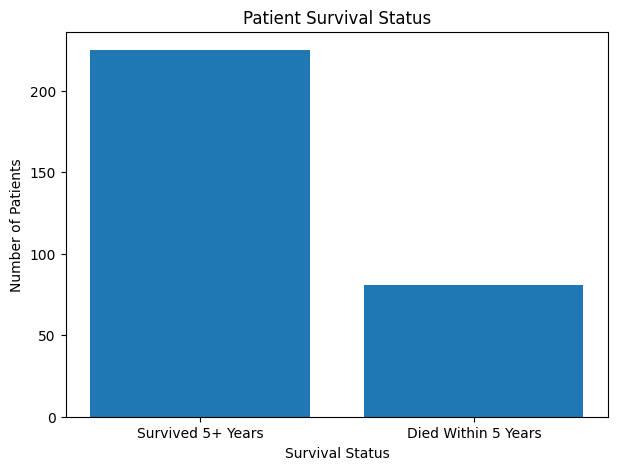

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["Survived 5+ Years", "Died Within 5 Years"],
    [survived, died]
)

plt.title("Patient Survival Status")
plt.xlabel("Survival Status")
plt.ylabel("Number of Patients")

plt.show()

Q2. Find the average, median, minimum and maximum age of patient

In [ ]:
average_age = df["Age"].mean()

print("Average Age:", average_age)

Average Age: 52.45751633986928


In [ ]:
median_age = df["Age"].median()

print("Median Age:", median_age)

Median Age: 52.0


In [ ]:
minimum_age = df["Age"].min()

print("Minimum Age:", minimum_age)

Minimum Age: 30


In [ ]:
maximum_age = df["Age"].max()

print("Maximum Age:", maximum_age)

Maximum Age: 83


In [ ]:
#ALL STATICS TOGETHER
print("Age Analysis")
print("--------------------")

print("Average Age:", df["Age"].mean())
print("Median Age:", df["Age"].median())
print("Minimum Age:", df["Age"].min())
print("Maximum Age:", df["Age"].max())

Age Analysis
--------------------
Average Age: 52.45751633986928
Median Age: 52.0
Minimum Age: 30
Maximum Age: 83


Observation:
The average age of patients is approximately 52.46 years. The median age is 52 years. The minimum age is 30 years, and the maximum age is 83 years. This indicates that the dataset includes patients from different age groups.

Q3. Calculate the average number of positive axillary nodes.

In [ ]:
average_nodes = df["Positive_Axillary_Nodes"].mean()

print("Average Positive Axillary Nodes:", average_nodes)

Average Positive Axillary Nodes: 4.026143790849673


Observation:
The average number of positive axillary nodes is approximately 4.03. This represents the average number of positive axillary nodes among all patients in the dataset.

Q4. Compare average age and average positive nodes between the two survival groups.

In [ ]:
# Group patients according to survival status

group_analysis = df.groupby("Survival_Status").agg({
    "Age": "mean",
    "Positive_Axillary_Nodes": "mean"
})

print(group_analysis)

                       Age  Positive_Axillary_Nodes
Survival_Status                                    
1                52.017778                 2.791111
2                53.679012                 7.456790


PROJECT REPORT: The patients who survived for 5 years or longer had an average age of 52.02 years and 2.79 positive axillary nodes. The patients who died within 5 years had an average age of 53.68 years and 7.46 positive axillary nodes. The second group had a higher average number of positive axillary nodes."

Q5: Year wise distribution of operations

ANALYSIS:The objective is to count the number of patients operated on in each year and identify the year with the maximum number of operations.

In [ ]:
year_count = df["Operation_Year"].value_counts().sort_index()

print("Patients in each year:")
print(year_count)

print("\nYear with maximum patients:",
      year_count.idxmax() + 1900)

print("Maximum patients:", year_count.max())

Patients in each year:
Operation_Year
58    36
59    27
60    28
61    26
62    23
63    30
64    31
65    28
66    28
67    25
68    13
69    11
Name: count, dtype: int64

Year with maximum patients: 1958
Maximum patients: 36


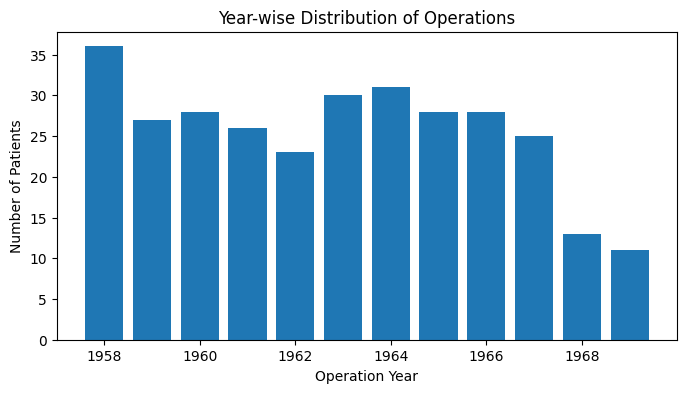

In [ ]:
plt.figure(figsize=(8, 4))

plt.bar(year_count.index + 1900, year_count.values)

plt.xlabel("Operation Year")
plt.ylabel("Number of Patients")
plt.title("Year-wise Distribution of Operations")

plt.show()

Observation
The analysis shows that the number of operations varies across different years. The year with the highest patient count represents the year with the maximum recorded operations in the dataset.

Q6. Missing Values and Duplicate Records

Analysis
The objective is to check missing values and duplicate records to evaluate the quality and completeness of the dataset.

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:",
      df.isnull().sum().sum())

print("\nTotal Duplicate Records:",
      df.duplicated().sum())

print("\nDataset Shape:", df.shape)

Missing Values:
Age                        0
Operation_Year             0
Positive_Axillary_Nodes    0
Survival_Status            0
dtype: int64

Total Missing Values: 0

Total Duplicate Records: 17

Dataset Shape: (306, 4)


Observation :
The dataset contains 306 rows and 4 columns. There are no missing values, but 17 duplicate records are present. Therefore, the dataset is complete in terms of missing values but contains some repeated entries.